# Waste Sorting Classifier (PyTorch + Colab)


## 1. Setup

In [1]:
!pip -q install gradio

In [2]:
import torch, torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from huggingface_hub import hf_hub_download
from pathlib import Path
import zipfile
from torch.utils.data import Subset
from torchvision.datasets import ImageFolder
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

Using: cuda


## 2. Our Datasets

dataset-resized.zip: reconstructing file:   0%|          |  0.00B / 42.8MB            

dataset-resized.zip: downloading bytes:           |  0.00B            

Data folder: trashnet_data/dataset-resized
['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash'] | total images: 2527


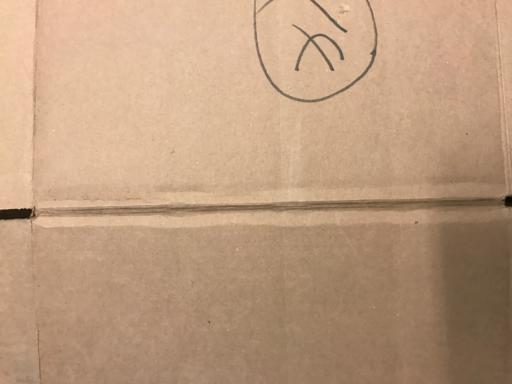

In [3]:
zip_path = hf_hub_download(repo_id="garythung/trashnet", filename="dataset-resized.zip", repo_type="dataset")
with zipfile.ZipFile(zip_path) as z:
    z.extractall("trashnet_data")

root = next(p for p in Path("trashnet_data").rglob("*") if p.is_dir() and (p / "glass").is_dir())
print("Data folder:", root)

full = ImageFolder(root)
class_names = full.classes
print(class_names, "| total images:", len(full))
full[0][0]

## 3. Split + transforms (augmentation only on train)

In [4]:
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # ImageNet stats (needed for pretrained model)

train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_full = ImageFolder(root, transform=train_tf)
eval_full  = ImageFolder(root, transform=eval_tf)

targets = np.array(full.targets)
idx = np.arange(len(targets))
train_idx, temp_idx = train_test_split(idx, test_size=0.2, stratify=targets, random_state=42)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.5, stratify=targets[temp_idx], random_state=42)
print(len(train_idx), len(val_idx), len(test_idx))

train_dl = DataLoader(Subset(train_full, train_idx), batch_size=32, shuffle=True, num_workers=2)
val_dl   = DataLoader(Subset(eval_full, val_idx), batch_size=32, num_workers=2)
test_dl  = DataLoader(Subset(eval_full, test_idx), batch_size=32, num_workers=2)

2021 253 253


## 4. Model: pretrained ResNet18 with a new final layer

In [5]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, len(class_names))
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=3e-4)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 225MB/s]


## 5. Train

In [6]:
def run_epoch(dl, train=True):
    model.train() if train else model.eval()
    total_loss, correct, n = 0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

EPOCHS = 8
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val = 0

for epoch in range(EPOCHS):
    tl, ta = run_epoch(train_dl, train=True)
    vl, va = run_epoch(val_dl, train=False)
    for k, v in zip(history, [tl, vl, ta, va]):
        history[k].append(v)
    if va > best_val:
        best_val = va
        torch.save(model.state_dict(), "best_model.pt")
    print(f"Epoch {epoch+1}/{EPOCHS} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f}")

Epoch 1/8 | train loss 0.729 acc 0.733 | val loss 0.715 acc 0.767
Epoch 2/8 | train loss 0.401 acc 0.862 | val loss 0.713 acc 0.783
Epoch 3/8 | train loss 0.302 acc 0.895 | val loss 0.427 acc 0.866
Epoch 4/8 | train loss 0.262 acc 0.916 | val loss 0.364 acc 0.870
Epoch 5/8 | train loss 0.217 acc 0.925 | val loss 0.283 acc 0.893
Epoch 6/8 | train loss 0.137 acc 0.952 | val loss 0.348 acc 0.881
Epoch 7/8 | train loss 0.128 acc 0.958 | val loss 0.358 acc 0.893
Epoch 8/8 | train loss 0.101 acc 0.966 | val loss 0.191 acc 0.937


## 6. Curves

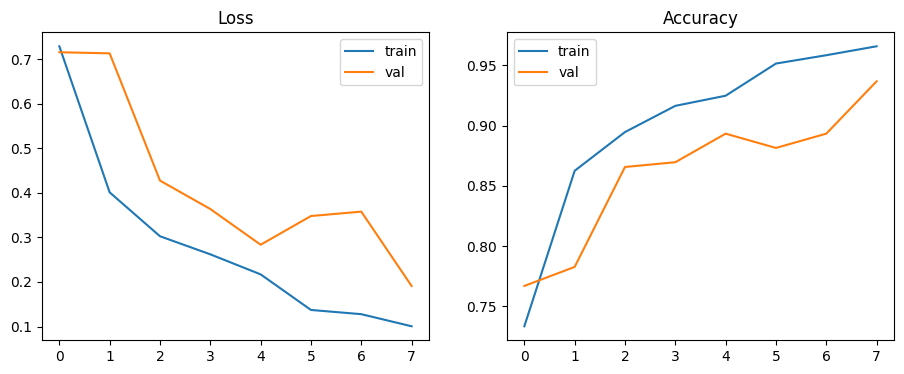

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history["train_loss"], label="train"); ax[0].plot(history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history["train_acc"], label="train"); ax[1].plot(history["val_acc"], label="val")
ax[1].set_title("Accuracy"); ax[1].legend()
plt.show()

## 7. Final test accuracy + confusion matrix

Test accuracy: 0.9011857707509882


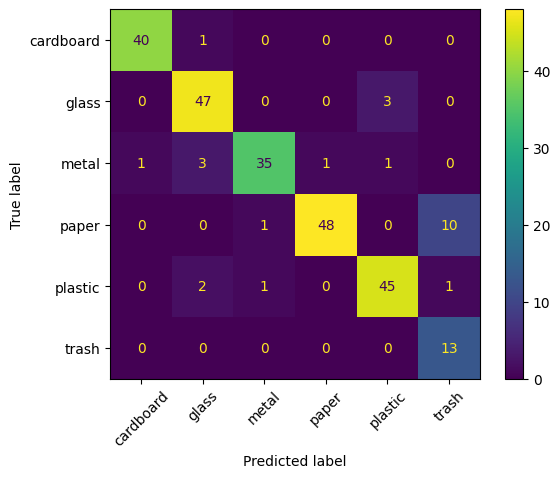

In [8]:
model.load_state_dict(torch.load("best_model.pt"))
model.eval()

preds, labels = [], []
with torch.no_grad():
    for x, y in test_dl:
        out = model(x.to(device))
        preds += out.argmax(1).cpu().tolist()
        labels += y.tolist()

print("Test accuracy:", np.mean(np.array(preds) == np.array(labels)))
cm = confusion_matrix(labels, preds)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(xticks_rotation=45)
plt.show()

## 8. Try your own pic

Saving trash.jpg to trash.jpg


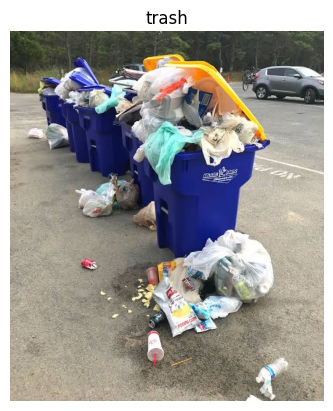

{'cardboard': 0.3291633725166321, 'glass': 8.099289698293433e-05, 'metal': 8.06135285529308e-05, 'paper': 0.0006616881000809371, 'plastic': 0.0035443513188511133, 'trash': 0.6664690375328064}


In [9]:
from google.colab import files
from PIL import Image
import io

def predict(img):
    model.eval()
    x = eval_tf(img.convert("RGB")).unsqueeze(0).to(device)
    with torch.no_grad():
        probs = torch.softmax(model(x), dim=1)[0].cpu()
    return {class_names[i]: float(probs[i]) for i in range(len(class_names))}

uploaded = files.upload()
for name, data in uploaded.items():
    img = Image.open(io.BytesIO(data))
    result = predict(img)
    plt.imshow(img); plt.axis("off")
    plt.title(max(result, key=result.get)); plt.show()
    print(result)

## 9. Stretch goal: Gradio demo

In [10]:
import gradio as gr
demo = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil"),
    outputs=gr.Label(num_top_classes=3),
    title="Waste Sorting Classifier",
)
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://71aad4107aaa421d01.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
